# SVM Kernels — Decision Boundaries on Non-Linear Data

Comparing linear, polynomial, and RBF SVM kernels on the classic `make_moons` and `make_circles` toy datasets, plus a look at how the regularization parameter `C` reshapes the decision margin.


In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons, make_circles
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

In [12]:
X_moons, y_moons = make_moons(n_samples=600, noise=0.25, random_state=42)
X_circles, y_circles = make_circles(n_samples=600, factor=0.5, noise=0.15, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X_moons, y_moons, test_size=0.2, random_state=42
)

## Training with different kernels

In [13]:
kernels = ['linear', 'poly', 'rbf']
kernel_names = ['Linear Kernel', 'Polynomial Kernel (Poly)', 'Radial Basis Function (RBF)']
models = {}
accuracies = {}

for kernel in kernels:
    clf = SVC(kernel=kernel, C=1.0, gamma='scale', random_state=42)
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    
    models[kernel] = clf
    accuracies[kernel] = accuracy_score(y_test, y_pred)
    print(f"Accuracy ({kernel}): {accuracies[kernel]:.4f}")

Accuracy (linear): 0.8417
Accuracy (poly): 0.8833
Accuracy (rbf): 0.9083


## Decision Boundaries

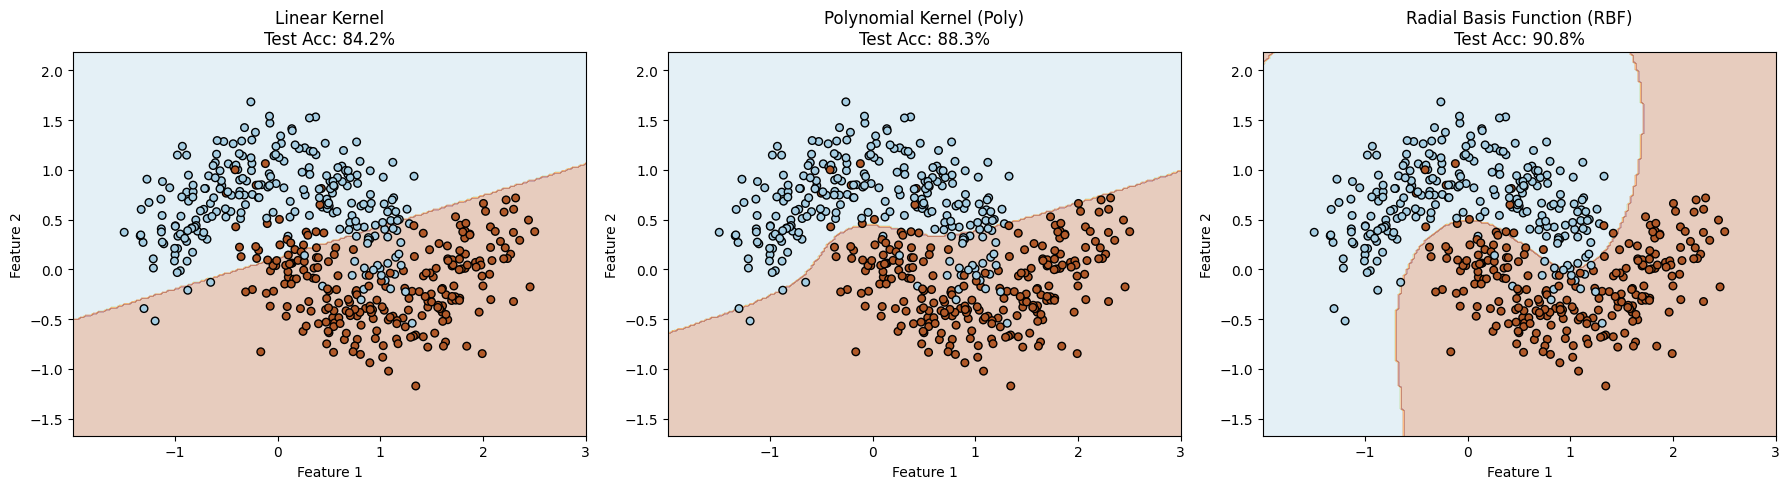

In [14]:
def plot_decision_boundary(clf, X, y, title, ax):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                         np.linspace(y_min, y_max, 200))
    
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    #dec bound
    ax.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.Paired)
    #data points
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.Paired, edgecolors='k', s=30)
    ax.set_title(title)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, kernel in enumerate(kernels):
    title = f"{kernel_names[i]}\nTest Acc: {accuracies[kernel]*100:.1f}%"
    plot_decision_boundary(models[kernel], X_train, y_train, title, axes[i])

plt.tight_layout()
plt.show()

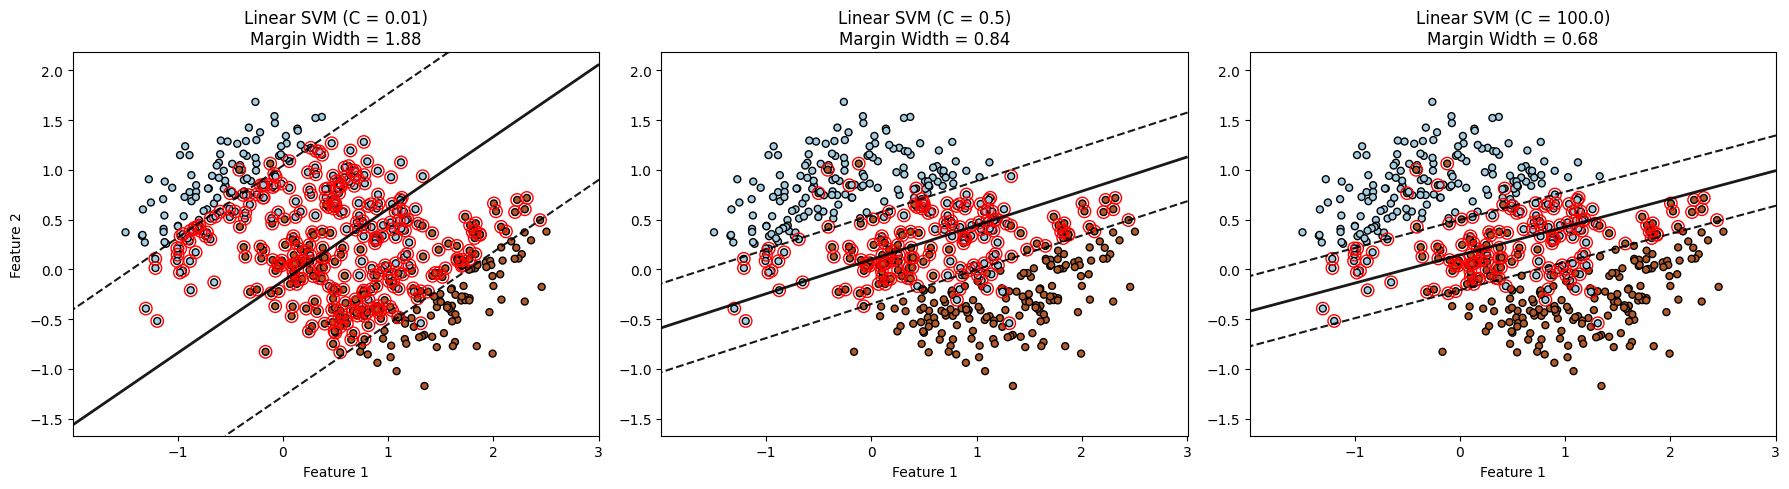

In [15]:

C_values = [0.01, 0.5, 100.0]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, C in enumerate(C_values):
    clf = SVC(kernel='linear', C=C, random_state=42)
    clf.fit(X_train, y_train)
    
    ax = axes[i]
    
    x_min, x_max = X_train[:, 0].min() - 0.5, X_train[:, 0].max() + 0.5
    y_min, y_max = X_train[:, 1].min() - 0.5, X_train[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                         np.linspace(y_min, y_max, 200))
    
    #  decision_function output
    Z = clf.decision_function(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=plt.cm.Paired, edgecolors='k', s=25)
    
    #    (0) DB and margin   (-1  +1)
    ax.contour(xx, yy, Z, levels=[-1, 0, 1], alpha=0.9,
               linestyles=['--', '-', '--'], colors='black', linewidths=[1.5, 2, 1.5])
    
    #  SV  
    ax.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1], s=80,
               linewidth=1, facecolors='none', edgecolors='red')
    
    #   MARGin width  (Margin Width = 2 / ||w||)
    w = clf.coef_[0]
    margin_width = 2 / np.linalg.norm(w)
    
    ax.set_title(f"Linear SVM (C = {C})\nMargin Width = {margin_width:.2f}")
    ax.set_xlabel("Feature 1")
    if i == 0:
        ax.set_ylabel("Feature 2")

plt.tight_layout()
plt.show()

### The Two-Moons Data Is Fully Non-Linear

**Linear kernel (84.17% accuracy):** the decision boundary is a straight line. Since the
data forms interleaving crescents, a straight line can't separate the two classes well,
leading to high error on both train and test sets (underfitting).

**Polynomial kernel (88.33% accuracy):** produces a curved boundary, more flexible than a
straight line, and scores higher accuracy. Still, it isn't ideal for the tightly
interlocking crescent shapes and misclassifies points near the tips.

**RBF kernel (90.83% accuracy):** the best result. The decision boundary elegantly
follows the curvature of the data and wraps around the crescents. The margin (dashed
lines) shows the model finding a sensible separation between the two non-linear classes —
making RBF the best choice for this dataset.


### Effect of the Regularization Parameter `C` on Margin Width

**Large `C`:** the penalty for margin violations (points inside the margin) is very high.
The model tries hard not to misclassify any point, which produces a narrower margin
(higher risk of overfitting).

**Small `C`:** the penalty for errors is low, so the model allows more points inside the
margin. This produces a wider margin with potentially better generalization, at the cost
of more training error.


### The Soft-Margin SVM Objective

The soft-margin SVM objective is defined as:

$$\min_{w, b, \xi} \frac{1}{2} \|w\|^2 + C \sum_{i=1}^{n} \xi_i$$

subject to:

$$y_i(w^T \phi(x_i) + b) \ge 1 - \xi_i, \qquad \xi_i \ge 0$$

**What each term does:**

- $\frac{1}{2} \|w\|^2$ — maximizes the margin. Minimizing the norm of the weight vector
  $w$ is equivalent to maximizing the distance between the decision boundaries.
- $C$ — the regularization parameter that balances "widen the margin" against "reduce
  classification error."
- $\sum_{i=1}^{n} \xi_i$ — the total amount of allowed slack (margin violation) across
  all samples.
- $\xi_i$ — a slack variable per sample, allowing some points to sit inside the margin
  (or even on the wrong side of the boundary) so the model can fit noisy data better.
